# 11 · Ion exchange and chromatography

Two more fixed-bed separations: ion exchange swaps ions on a resin (water softening, deionisation, metal
recovery) and chromatography separates solutes by how strongly they adsorb as a pulse travels down a column
(the workhorse of biotechnology purification and of analysis). Both are adsorption with a twist: an
equilibrium written as a selectivity, and a column run as pulses rather than to breakthrough. This notebook
models both with the tools of notebook 10 and the plate theory of chromatography.

**What you will learn**
- write ion-exchange equilibria as selectivities
- size a softener cycle and its regeneration
- use the plate model of chromatography and compute resolution
- explain the van Deemter optimum

**Before you start:** notebook 10  ·  **Time:** about 45 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import adsorption as ad
from scipy import special
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Ion-exchange equilibrium: selectivity

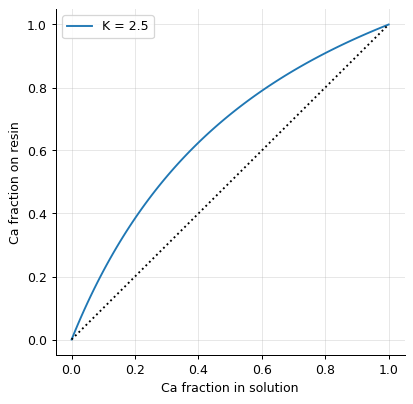

the resin prefers calcium: a hard water with 10 % Ca equivalents loads the resin to 0.217


In [2]:
K_sel = 2.5                                                          # selectivity of the resin for Ca2+ over Na+ (equivalents, simplified binary exchange)
x = np.linspace(0, 1, 100)                                           # equivalent fraction of Ca in solution
y = K_sel * x / (1 + (K_sel - 1) * x)                                # equivalent fraction on the resin (constant-selectivity form)
fig, ax = plt.subplots(figsize=(5, 5)); ax.plot(x, y, label=f"K = {K_sel}"); ax.plot([0, 1], [0, 1], "k:"); ax.set(xlabel="Ca fraction in solution", ylabel="Ca fraction on resin"); ax.legend(); plt.show()
print("the resin prefers calcium: a hard water with 10 % Ca equivalents loads the resin to", round(float(K_sel * 0.1 / (1 + (K_sel - 1) * 0.1)), 3))

Ion exchange is stoichiometric - one calcium replaces two sodiums - and its equilibrium looks exactly like
the constant-relative-volatility curve of distillation, with the selectivity as α. A resin that prefers the
ion to be removed gives a favourable isotherm and a sharp exchange front; regeneration with a concentrated
brine reverses the preference by mass action.

## Softening a water: capacity and cycle

In [3]:
capacity = 1.8                                                       # eq/L of resin
hardness = 4.0e-3                                                    # eq/L of Ca + Mg in the feed
flow = 10.0                                                          # m3/h
V_resin = 0.5                                                        # m3
t_cycle = V_resin * capacity * 1e3 / (hardness * 1e3 * flow)          # equivalents in the bed / equivalents fed per hour
print(f"a 0.5 m3 bed treats hard water (4 meq/L) at 10 m3/h for {t_cycle:.1f} h before exhaustion (ideal); with 70 % of the bed usable at breakthrough: {0.7 * t_cycle:.1f} h")
print(f"regeneration with 10 % NaCl (1.7 eq/L) at 150 % of stoichiometry needs {1.5 * V_resin * capacity / 1.7:.2f} m3 of brine per cycle")

a 0.5 m3 bed treats hard water (4 meq/L) at 10 m3/h for 22.5 h before exhaustion (ideal); with 70 % of the bed usable at breakthrough: 15.7 h
regeneration with 10 % NaCl (1.7 eq/L) at 150 % of stoichiometry needs 0.79 m3 of brine per cycle


The cycle time is the bed's capacity over the ionic load, reduced by the mass-transfer zone exactly as in
adsorption; the regenerant demand is the same equivalents plus an excess, which is where the salt and the
waste come from. A softener is a fixed-bed adsorber with an equivalents balance.

## Chromatography: the plate model

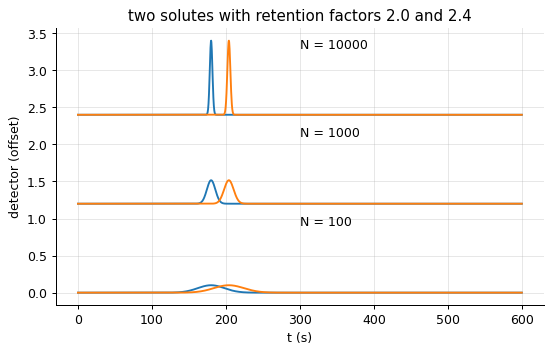

N =   100 plates: resolution R_s = 0.31
N =  1000 plates: resolution R_s = 0.99
N = 10000 plates: resolution R_s = 3.12  (baseline separated)


In [4]:
def peak(t, t_R, N_plates):
    sigma = t_R / np.sqrt(N_plates)
    return np.exp(-0.5 * ((t - t_R) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
t0 = 60.0                                                            # s, the column's dead time
t = np.linspace(0, 600, 2000)
fig, ax = plt.subplots()
for N_plates in (100, 1000, 10000):
    for k_ret, lbl in ((2.0, "A"), (2.4, "B")):
        t_R = t0 * (1 + k_ret)
        ax.plot(t, peak(t, t_R, N_plates) / peak(t, t_R, 10000).max() + (0 if N_plates == 100 else 1.2 if N_plates == 1000 else 2.4), "C0" if lbl == "A" else "C1")
ax.text(300, 0.9, "N = 100"); ax.text(300, 2.1, "N = 1000"); ax.text(300, 3.3, "N = 10000"); ax.set(xlabel="t (s)", ylabel="detector (offset)", title="two solutes with retention factors 2.0 and 2.4"); plt.show()
for N_plates in (100, 1000, 10000):
    tA, tB = t0 * 3.0, t0 * 3.4
    Rs = (tB - tA) / (2 * (tA + tB) / np.sqrt(N_plates))
    print(f"N = {N_plates:5d} plates: resolution R_s = {Rs:.2f}" + ("  (baseline separated)" if Rs >= 1.5 else ""))

A solute travels at the mobile-phase velocity divided by $1 + k$, where $k$ is the retention factor (how much
of it sits on the stationary phase); different $k$ separate the peaks and band broadening merges them. In
the plate model each peak is a Gaussian whose width falls as $1/\sqrt{N}$: two solutes differing by 20 % in
retention need ten thousand plates for baseline resolution - the reason HPLC columns are packed with
micron particles.

## Van Deemter: why there is an optimum velocity

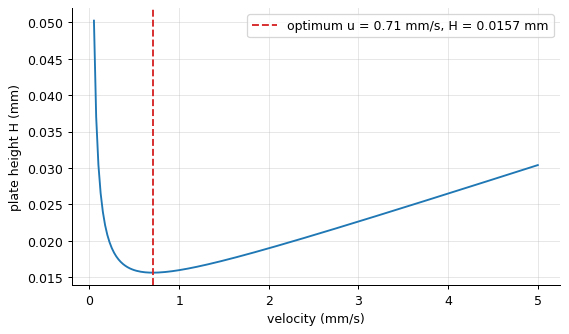

In [5]:
u = np.linspace(0.05, 5, 200)                                        # mm/s
A_, B_, C_ = 0.01, 0.002, 0.004                                      # mm, mm2/s, s (illustrative)
H = A_ + B_ / u + C_ * u
u_opt = np.sqrt(B_ / C_)
plt.plot(u, H); plt.axvline(u_opt, color="C3", ls="--", label=f"optimum u = {u_opt:.2f} mm/s, H = {A_ + 2*np.sqrt(B_*C_):.4f} mm"); plt.xlabel("velocity (mm/s)"); plt.ylabel("plate height H (mm)"); plt.legend(); plt.show()

The plate height has three contributions: eddy diffusion (independent of velocity), longitudinal diffusion
(worse when the pulse lingers) and mass-transfer lag (worse when it rushes); their sum has a minimum at
$u = \sqrt{B/C}$. Chromatographers run near it, or faster with smaller particles that shrink $C$ -
the same competition between diffusion and residence time as in every column in this course.

## Inside the algorithm: resolution from plates

In [6]:
N_ = 1000
tA_, tB_ = t0 * 3.0, t0 * 3.4
print("by hand: R_s =", (tB_ - tA_) / (2 * (tA_ + tB_) / np.sqrt(N_)))

by hand: R_s = 0.9882117688026184


## Exercises
1. A deioniser uses a cation resin (1.8 eq/L) and an anion resin (1.2 eq/L) in series to treat water with 3 meq/L of cations and 3 meq/L of anions at 5 m3/h. Size each bed for a 24 h cycle at 75 % utilisation, and compute the acid and base needed for regeneration at 200 % of stoichiometry.
2. Two proteins have retention factors 1.5 and 1.8 on a 20 cm column with a plate height of 20 um. Find the resolution. How long must the column be for R_s = 1.5, and how does the run time scale?
3. **Implement it yourself:** simulate the two chromatographic peaks as Gaussians for N = 500 and compute the resolution from the peak widths at half height (w = 2.355 sigma) instead of the formula.